# Hälsostudie - Del2

## 1. Functions and Modules

Jag har flyttar kod från del 1 till återvändbara funktioner i python files. 

Impotertat funktionerna till notebooken för att kontrollera att de fungerar och ger samma resultat som i Del 1.

In [4]:
import sys
from pathlib import Path

# Hitta projektets huvudmapp
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

# Importera funktioner från vår modul
from src.analysis_utils import (
    load_health_data,
    calculate_summary_stats,
    calculate_disease_proportion,
    simulate_disease,
    calculate_bp_confidence_interval,
    test_smoking_bp
)

In [5]:
df = load_health_data(
    project_root / "data" / "health_study_dataset.csv"
)

print(df.shape)

(800, 9)


In [6]:
print("Current directory:", Path.cwd())
print("Project root:", project_root)
print("Module exists:", (project_root / "src" / "analysis_utils.py").exists())

Current directory: /mnt/c/Users/luisa/ECutbilding/health-study/notebooks
Project root: /mnt/c/Users/luisa/ECutbilding/health-study
Module exists: True


## Testa funktioner 

### 1. Summary

In [7]:
print("SUMMARY STATISTICS")
print(calculate_summary_stats(df))

SUMMARY STATISTICS
          age  weight  height  systolic_bp  cholesterol
mean    49.43   73.41  171.85       149.18         4.93
median  50.00   73.20  171.35       149.40         4.97
min     18.00   33.70  144.40       106.80         2.50
max     90.00  114.40  200.40       185.90         7.88


### 2. Disease proporktion

In [8]:
print("\nDISEASE PROPORTION")
disease_probability = calculate_disease_proportion(df)
print(f"Disease proportion: {disease_probability:.4%}")


DISEASE PROPORTION
Disease proportion: 5.8750%


### 3. Disease simulation

In [9]:
print("\nDISEASE SIMULATION")
simulation = simulate_disease(disease_probability, n=1000, seed=42)
print("Disease cases:", simulation.sum())
print(f"Simulated proportion: {simulation.mean():.2%}")


DISEASE SIMULATION
Disease cases: 54
Simulated proportion: 5.40%


### 4. Confidence Intervals

In [10]:
print("\nCONFIDENCE INTERVALS")
normal_ci = calculate_bp_confidence_interval(df, method="normal")
bootstrap_ci = calculate_bp_confidence_interval(df, method="bootstrap")

print("Normal:", tuple(round(x, 2) for x in normal_ci))
print("Bootstrap:", tuple(round(x, 2) for x in bootstrap_ci))


CONFIDENCE INTERVALS
Normal: (148.29, 150.07)
Bootstrap: (148.3, 150.06)


### 5. Hypothes test

In [11]:
print("\nHYPOTHESIS TESTING")
t_stat, p_value = test_smoking_bp(df)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")


HYPOTHESIS TESTING
t-statistic: 0.4503
p-value: 0.3264


### 1.1 Functiones och Modules

Jag har skapat 6 funktioner: 

- load_health_data() 
  -  Läser in datasetet.

- calculate_summary_stats() 
  -  Beräknar medelvärde, median, min och max.

- calculate_disease_proportion() 
  -  Beräknar andelen deltagare med sjukdomen.

- simulate_disease() 
  - Simulerar sjukdom med NumPy.

- calculate_bp_confidence_interval() 
  - Beräknar konfidensintervall med normalapproximation eller bootstrap.

- test_smoking_bp() 
  -  Jämför blodtryck mellan rökare och icke-rökare med Welch's t-test.

**Varför använder vi funktioner och moduler?
**
Vi använder funktioner för att undvika att upprepa samma kod och för att kunna återanvända våra analyser.

Genom att lägga funktionerna i en separat modul blir notebooken enklare att läsa och koden lättare att underhålla.

**Resultat:** Vi har testat funktionerna och fått samma statistiska resultat som i Del 1.

## 2. HealthAnalyzer Class

Klassen använder funktionerna från analysis_utils.py för att utföra olika analyser. Den kan ocksp skapa grafer. 

Använder klassen för att samla flera funktioner på ett ställe och undvika att skriva samma kod flera gånger. 

In [12]:
from src.analysis_utils import load_health_data
from src.health_analyzer import HealthAnalyzer

# Ladda dataset
df = load_health_data(
    project_root / "data" / "health_study_dataset.csv"
)
# skapa ett objekt med dataset
analyzer = HealthAnalyzer(df)

print("Dataset shape:", analyzer.df.shape)


Dataset shape: (800, 9)


In [14]:
# Testa metoder från HealthAnalyzer

display(analyzer.summary_statistics())

print("Disease proportion:", analyzer.disease_proportion())
print("Disease simulation:", analyzer.disease_simulation())

print("Normal CI:", analyzer.confidence_interval("normal"))
print("Bootstrap CI:", analyzer.confidence_interval("bootstrap"))

t, p = analyzer.smoking_bp_test()
print(f"t-statistic: {t:.4f}")
print(f"p-value: {p:.4f}")

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


Disease proportion: 0.05875
Disease simulation: 0.054
Normal CI: (148.2921066505355, 150.06514334946453)
Bootstrap CI: (148.304625, 150.06331875)
t-statistic: 0.4503
p-value: 0.3264


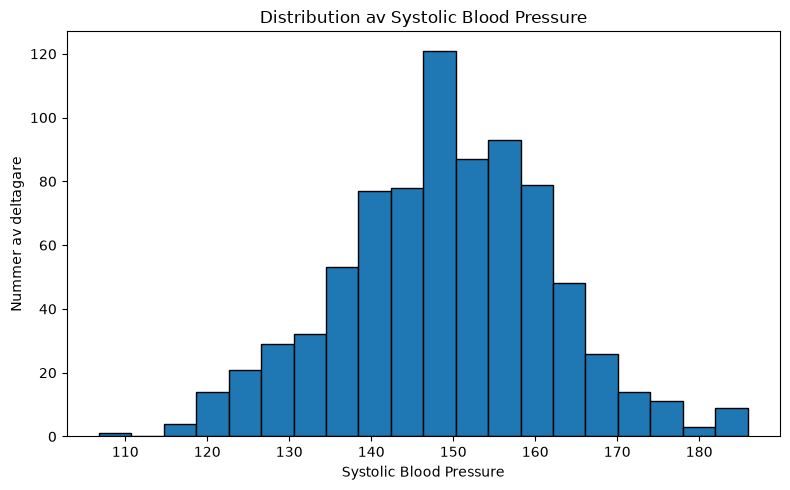

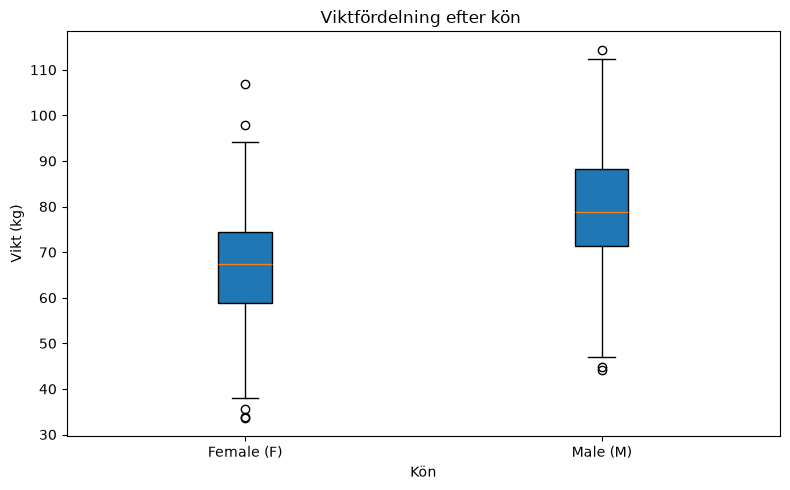

In [15]:
import matplotlib.pyplot as plt

# Histogem över bp
fig_bp = analyzer.plot_bp_distribution()
display(fig_bp)
plt.close(fig_bp)

# Boxplot över vikt per kön
fig_weight = analyzer.plot_weight_by_gender()
display(fig_weight)
plt.close(fig_weight)

### 2.1 HealthAnalyzer 

Klassen använder funktionerna från analysis_utils.py för att beräkna statistik, simulera sjukdom, beräkna konfidensintervall och utföra hypotesprövning. 

Har också lagt till två metoder för visualireing:
- histogram över bp
- boxplot över vikt per kön

Man använder en klass för att kunna arbeta med samma dataset utan att behöva skicka det till varje funktion. Det gör koden mer organiserad och enklare att återvända